# Multilevel option pricing

Author: Fred J. Hickernell · MATH 565, Fall 2026

Companion to [Selected Topics: Multilevel Monte Carlo](https://fjhickernell.github.io/MATH565Fall2026/slides/05-selected-topics.html#multilevel-monte-carlo)

Use cheap Asian-option approximations and coupled corrections to estimate an expensive price. See how **point counts differ from work**, compare IID with randomized Sobol' sampling, and separate sampling error from time-discretization bias.

Adapted and extended from QMCPy's [Multilevel (Q)MC for Option Pricing](https://qmcsoftware.org/qmcpy/demos/asian-option-mlqmc/). All comparisons below use the same explicitly specified contract and model. The main experiment holds the finest grid fixed; the optional adaptive algorithms choose their own grids.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fjhickernell/MATH565Fall2026/blob/main/notebooks/performance/MultilevelOptionPricing.ipynb)

Run All with the course `qmcpy` kernel. After changing parameters, rerun from the beginning. Colab uses the course's recorded dependency commits once this notebook is published.

### Reading guide

- **Parts 1–2:** define the option and show how fine and coarse paths are coupled
- **Parts 3–4:** measure IID variance and cost, then choose sample counts
- **Part 5:** choose counts for randomized Sobol' sampling
- **Parts 6–7:** build an independent numerical reference and compare sampling accuracy
- **Part 8:** investigate approximation bias by changing the grid
- **Part 9:** optional native adaptive algorithms

A **single-level** estimate averages payoffs on the finest grid. **MLMC** adds averages of coupled corrections using IID samples. **MLQMC** uses randomized Sobol' points for those level averages. Parts 1–7 target one fixed finest-grid price; this differs from the continuous-time limiting price.

In the parameter cell, `L` is the number of grid levels, `REFINEMENT` is the ratio of adjacent grids, `R` is the number of independent Sobol' randomizations inside a price estimate, and `TRIALS` is the number of repeated price estimates used for the comparison. The default `L=4` is the shorter classroom run; `L=5` adds a finer level.


In [1]:
from pathlib import Path
import shutil
import subprocess
import sys
import time

NOTEBOOK_START_TIME = time.perf_counter()

colab = "google.colab" in sys.modules
if colab:
    print("Setting up this course's recorded classlib, QMCPy, and TeX; this may take several minutes …")
    course_checkout = Path("/content/MATH565Fall2026")
    if not course_checkout.exists():
        subprocess.run(
            [
                "git", "clone", "--quiet", "--depth", "1",
                "https://github.com/fjhickernell/MATH565Fall2026.git",
                str(course_checkout),
            ],
            check=True,
        )
    subprocess.run(
        [
            "git", "-C", str(course_checkout),
            "-c", "submodule.classlib.url=https://github.com/fjhickernell/HickernellAcademicLib.git",
            "-c", "submodule.qmcpy.url=https://github.com/QMCSoftware/qmcpy.git",
            "submodule", "update", "--init", "classlib", "qmcpy",
        ],
        check=True,
    )
    if shutil.which("latex") is None:
        subprocess.run(
            [
                "apt-get", "-qq", "install", "-y",
                "cm-super", "dvipng", "texlive-latex-extra",
                "texlive-latex-recommended",
            ],
            check=True,
        )
    subprocess.run(
        [
            sys.executable, "-m", "pip", "install", "-q",
            str(course_checkout / "classlib"),
            str(course_checkout / "qmcpy"),
        ],
        check=True,
    )
    print("Colab setup complete.")
    print("For faster repeated work, use the local `qmcpy` environment.")

In [2]:
# Find the course checkout and import its recorded source versions.
search_start = course_checkout if colab else Path.cwd().resolve()
course_root = next((p for p in [search_start, *search_start.parents]
                    if (p / 'course-metadata.yml').is_file()
                    and (p / 'qmcpy/qmcpy').is_dir()), None)
if course_root is None:
    raise RuntimeError('Run from the MATH565Fall2026 checkout or use the Colab setup.')
for dependency in ['classlib', 'qmcpy']:
    sys.path.insert(0, str(course_root / dependency))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import qmcpy as qp
import classlib as cl
from IPython.display import display, Markdown

%matplotlib inline
cl.nbviz.init(use_tex=True)

SEED = 5651103
L = 4                         # Default: through 256 steps; set to 5 for 1,024
REFINEMENT = 4                # d_ell=4**ell: 4,16,64,256,1024 at L=5
R = 8                         # Independent Sobol' randomizations per estimate
PILOT_N = 512                 # IID pilot contributions at every level
RQMC_PILOT_SIZES = [32, 64, 128]
WORK_BUDGETS = [REFINEMENT**L * 2**12, REFINEMENT**L * 2**13]
TRIALS = 12                   # Fresh whole-estimator repetitions per design
BATCH = 1024                  # Bound memory, including reference computations
REF_N, REF_R = 2**15, 16       # Independent finite-grid numerical reference
REFINE_LEVELS = list(range(1, L+2))
REFINE_N, REFINE_R = 2**10, 8
RUN_CONTINUATION = False      # Optional final section; True runs all four solvers

MODEL = dict(option='ASIAN', call_put='CALL', start_price=100.,
             strike_price=100., interest_rate=.05, volatility=.2,
             t_final=1., asian_mean='ARITHMETIC',
             asian_mean_quadrature_rule='TRAPEZOIDAL',
             decomp_type='BrownianBridge', d_coarsest=4)
assert L >= 2 and R >= 2 and TRIALS >= 2
assert not RUN_CONTINUATION or R >= 4
assert all(n > 0 and n & (n-1) == 0 for n in RQMC_PILOT_SIZES + [REF_N, REFINE_N, BATCH])
levels = np.arange(1, L+1)
dimensions = REFINEMENT**levels
# Transparent time-step work proxy, not measured runtime:
# fine-grid work plus coarse payoff accumulation for a correction.
proxy_cost = dimensions.astype(float) + np.r_[0, dimensions[:-1]]
fine_cost = float(dimensions[-1])

def stream(*labels):
    return np.random.SeedSequence([SEED, *map(int, labels)])

print(f'QMCPy {qp.__version__}; source: {Path(qp.__file__).resolve()}')
print(f'Fixed target: {dimensions[-1]} time steps; {R} independent Sobol\' runs per estimate')
display(pd.DataFrame([MODEL]).drop(columns=['option', 'call_put', 'd_coarsest']))

QMCPy 2.4; source: /Users/fredhickernell/SoftwareRepositories/MATH565Fall2026/qmcpy/qmcpy/__init__.py
Fixed target: 256 time steps; 8 independent Sobol' runs per estimate


,start_price,strike_price,interest_rate,volatility,t_final,asian_mean,asian_mean_quadrature_rule,decomp_type
0,100.0,100.0,0.05,0.2,1.0,ARITHMETIC,TRAPEZOIDAL,BrownianBridge


## 1. One model, a hierarchy of price approximations

Here $S_0$ is the initial asset price, $K$ the strike, $r$ the interest rate, $\sigma$ the volatility, and $T$ the maturity. Write $(z)_+=\max(z,0)$. Under the risk-neutral model,
\begin{align*}
S(t)&=S_0\exp\{(r-\sigma^2/2)t+\sigma B(t)\},\\
A_d&=\frac{S_0/2+\sum_{j=1}^{d-1}S(jT/d)+S(T)/2}{d},\\
P_d&=e^{-rT}(A_d-K)_+,
\qquad \mu_d=\mathbb E(P_d).
\end{align*}
Here $A_d$ approximates the **continuous time average** $T^{-1}\int_0^T S(t)\,\mathrm dt$. Increasing $d$ improves that approximation. This differs from the fixed weekly monitoring in the earlier Asian-option variance-reduction notebook.

Use $d_\ell=4^\ell$, $\ell=1,\ldots,L$:
\begin{align*}
Y_1&=P_{d_1}, &Y_\ell&=P_{d_\ell}-P_{d_{\ell-1}},\\
\mu_{d_L}&=\sum_{\ell=1}^L\mathbb E(Y_\ell),
&\mu&=\lim_{d\to\infty}\mu_d.
\end{align*}

With $n_\ell$ contributions on level $\ell$, the reported price estimate is

$$
\widehat\mu_\ell=\frac{1}{n_\ell}\sum_{i=0}^{n_\ell-1}Y_{i,\ell},
\qquad \widehat\mu=\sum_{\ell=1}^L\widehat\mu_\ell.
$$

The two payoffs inside one correction share a path; the different level means use independent sample sets.

The main experiment estimates the **finite target** $\mu_{d_L}$. Its integration error is separate from $b_L=\mu-\mu_{d_L}$. An arithmetic Asian option has no exact price supplied here.

**Sampling map:** QMCPy transforms uniform inputs into a Brownian path, constructs the asset path $S(t)$ from that Brownian path, and evaluates discounted option payoffs. The payoff routine in the code receives asset prices. Brownian bridge changes the coordinate construction, not the target Brownian law. Sample indices start at zero; levels start at one. The main experiment refines by a factor of four. A coupled contribution reuses QMCPy's payoff routine on the full fine path and on every fourth value of that same path. The optional native adaptive solvers use their own factor-two hierarchy.

The Sobol' generator uses Gray ordering to evaluate bounded chunks. Every complete run still uses a power-of-two prefix; chunk boundaries do not create new randomizations or separate estimates.

In [3]:
def sampler(d, method, seed):
    if method == 'IID':
        return qp.IIDStdUniform(int(d), seed=seed)
    return qp.DigitalNetB2(int(d), seed=seed, randomize='LMS DS',
                          order='GRAY')


def option(ell, method, seed, correction=True):
    d = REFINEMENT**int(ell)
    fine = qp.FinancialOption(sampler(d, method, seed), **MODEL)
    if not correction:
        return fine
    # Reuse QMCPy's payoff routine on the same asset path at two resolutions.
    # This coarse object's sampler is never called; only its g(path) is used.
    coarse = (qp.FinancialOption(qp.IIDStdUniform(d//REFINEMENT, seed=0), **MODEL)
              if ell>1 else None)
    def coupled_payoffs(stock):
        fine_payoff = fine.g(stock)
        coarse_payoff = (coarse.g(stock[..., REFINEMENT-1::REFINEMENT])
                         if coarse is not None else np.zeros_like(fine_payoff))
        return np.stack([coarse_payoff, fine_payoff])
    return qp.CustomFun(fine.true_measure, g=coupled_payoffs, dimension_indv=2)


def contributions(ell, n, method, seed, correction=True):
    """Complete generation, Brownian transformation, and payoff evaluation."""
    integrand = option(ell, method, seed, correction)
    for start in range(0, int(n), BATCH):
        y = integrand(n_min=start, n_max=min(start+BATCH, int(n)), warn=False)
        yield y[1]-y[0] if correction else y


def estimate(ell, n, method, seed, correction=True):
    total = sum(np.sum(y, dtype=np.float64)
                for y in contributions(ell, n, method, seed, correction))
    return float(total / n)


def replicated_means(ell, n, reps, labels, correction=True):
    return np.array([estimate(ell, n, 'Sobol', stream(*labels, rep), correction)
                     for rep in range(reps)])


def trap_payoff(stock):
    average = (MODEL['start_price']/2 + stock[..., :-1].sum(axis=-1)
               + stock[..., -1]/2) / stock.shape[-1]
    return np.exp(-MODEL['interest_rate']*MODEL['t_final']) * np.maximum(average-MODEL['strike_price'], 0)

# Native FinancialOption agrees with the displayed trapezoidal payoff.
check = option(3, 'IID', stream(0))
stock = check.true_measure(16)
expected = np.stack([trap_payoff(stock[..., REFINEMENT-1::REFINEMENT]), trap_payoff(stock)])
np.testing.assert_allclose(check.g(stock), expected, rtol=1e-13, atol=1e-13)
base = option(1, 'IID', stream(0, 1))
np.testing.assert_array_equal(base.g(base.true_measure(4))[0], np.zeros(4))
print('Payoff convention and base-level zero coarse contribution verified')

Payoff convention and base-level zero coarse contribution verified


## 2. Couple the driving Brownian path

For this illustration, use $4m$ fine increments over $[0,T]$, form
\begin{align*}
\Delta W_i^{\mathrm f}&\sim\operatorname{Norm}(0,T/(4m)),
&&i=0,\ldots,4m-1,\\
\Delta W_j^{\mathrm c}&=\Delta W_{4j}^{\mathrm f}+\Delta W_{4j+1}^{\mathrm f}+\Delta W_{4j+2}^{\mathrm f}+\Delta W_{4j+3}^{\mathrm f},
&&j=0,\ldots,m-1.
\end{align*}
The fine increments are independent. Each coarse increment has variance $4[T/(4m)]=T/m$, and different coarse increments use disjoint groups. Thus the coarse values have the correct Brownian law and equal every fourth fine Brownian value. Price both discretizations from this shared path; do not generate an unrelated coarse path for the correction. Coarse and fine **price approximations** can still differ. This illustration has 16 fine intervals and 4 coarse intervals; the later MLMC experiments use this same factor-four refinement.

A correction can be exactly zero on an individual path: if both coarse and fine averages are at or below the strike, both call payoffs are zero. This is what happens for path 2 in the default example; it does not imply zero correction on other paths.

Use a separate independent sample set for each level mean. For randomized Sobol', whole randomizations are independent between levels; points within one run are dependent. The earlier $f_d(\boldsymbol X_{1:d})$ notation assumes compatible hierarchical inputs: coarsening is not truncating the chronological fine-increment vector.

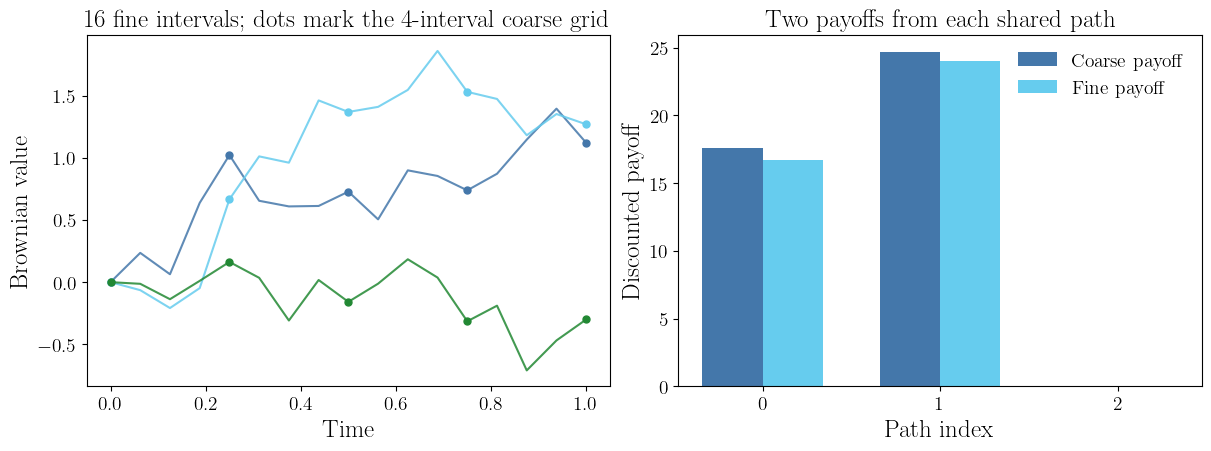

,coarse,fine,correction
path,,,
0,17.602077,16.724970,-0.877107
1,24.699560,24.048464,-0.651096
2,0.000000,0.000000,0.000000


In [4]:
d_demo = 16
refinement_demo = 4  # Four fine intervals for each coarse interval
brownian = qp.BrownianMotion(qp.IIDStdUniform(d_demo, seed=stream(1)),
                             t_final=MODEL['t_final'], decomp_type='BrownianBridge')
w_fine = brownian(3)
dw_fine = np.diff(np.c_[np.zeros(3), w_fine], axis=1)
dw_coarse = dw_fine.reshape(3, d_demo//refinement_demo, refinement_demo).sum(axis=-1)
w_coarse = np.cumsum(dw_coarse, axis=1)
np.testing.assert_allclose(w_coarse, w_fine[:, refinement_demo-1::refinement_demo], rtol=1e-12, atol=1e-12)
t_fine = np.linspace(0, MODEL['t_final'], d_demo+1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), constrained_layout=True)
for i in range(3):
    line, = axes[0].plot(t_fine, np.r_[0, w_fine[i]], alpha=.85)
    axes[0].plot(t_fine[::refinement_demo], np.r_[0, w_coarse[i]], 'o', color=line.get_color(), markersize=5)
axes[0].set(xlabel='Time', ylabel='Brownian value', title='16 fine intervals; dots mark the 4-interval coarse grid')
stock = MODEL['start_price'] * np.exp((MODEL['interest_rate']-MODEL['volatility']**2/2)
        * t_fine[1:] + MODEL['volatility']*w_fine)
fine_payoff, coarse_payoff = trap_payoff(stock), trap_payoff(stock[:, refinement_demo-1::refinement_demo])
axes[1].bar(np.arange(3)-.17, coarse_payoff, width=.34, label='Coarse payoff')
axes[1].bar(np.arange(3)+.17, fine_payoff, width=.34, label='Fine payoff')
axes[1].set(xlabel='Path index', ylabel='Discounted payoff', title='Two payoffs from each shared path', xticks=range(3))
axes[1].legend()
plt.show()
display(pd.DataFrame({'path':range(3), 'coarse':coarse_payoff, 'fine':fine_payoff,
                      'correction':fine_payoff-coarse_payoff}).set_index('path'))

## 3. Pilot the error and work at each level

For IID sampling, $V_\ell=\operatorname{var}(Y_\ell)$ and
$$
\operatorname{var}(\widehat\mu)=\sum_{\ell=1}^L V_\ell/n_\ell.
$$
Compare a coupled difference with a difference formed from **independent** fine and coarse paths. Their means agree, but their variances need not.

The work proxy is $c_1=d_1$ and $c_\ell=d_\ell+d_{\ell-1}$ for $\ell>1$, counting fine-grid processing and coarse payoff accumulation. It is an illustrative time-step model, not measured total runtime. The timings below include sampler construction, generation, Brownian transformation, and both payoff evaluations. Setup makes these small-batch timings imperfect per-point predictors.

We charge pilot proxy work to every design that uses the pilot. We freeze the resulting allocations and use fresh final samples; pilot data do not enter final estimates.

### What the levels mean

A **level is a grid resolution**, not a single path or a sample count. Write $P_d$ for the discounted payoff using $d$ monitoring steps. Level 1 samples $P_{d_1}$ itself; later levels sample $P_{d_\ell}-P_{d_{\ell-1}}$.

The level-guide table below is generated from the current settings, so it updates when `L` or `REFINEMENT` changes. Every row uses `PILOT_N` samples for the variance pilot. The two payoffs in a difference share one Brownian path; separate independent sample sets estimate the level means. Their exact means add to the finest-grid price. The pilot table contains noisy estimates, not the final reported price.


**Level guide** — a zero coarse-step count means no coarse payoff at the base level.

,fine_steps,coarse_steps,sampled_contribution,proxy_cost
level,,,,
1,4,0,base payoff,4.0
2,16,4,fine minus coarse,20.0
3,64,16,fine minus coarse,80.0
4,256,64,fine minus coarse,320.0


**Pilot measurements**

,steps,correction_mean,coupled_variance,independent_variance,proxy_cost,complete_batch_seconds,seconds_per_contribution
level,,,,,,,
1,4,6.115703,68.239153,64.630432,4.0,0.001733,0.000003
2,16,-0.004171,1.167988,133.861708,20.0,0.000922,0.000002
3,64,-0.018503,0.080396,113.221684,80.0,0.002266,0.000004
4,256,0.001989,0.004180,129.632198,320.0,0.016921,0.000033


Allocation pilot: 217,088 proxy work; pilot: 0.022 sec; complete diagnostic section: 0.044 sec


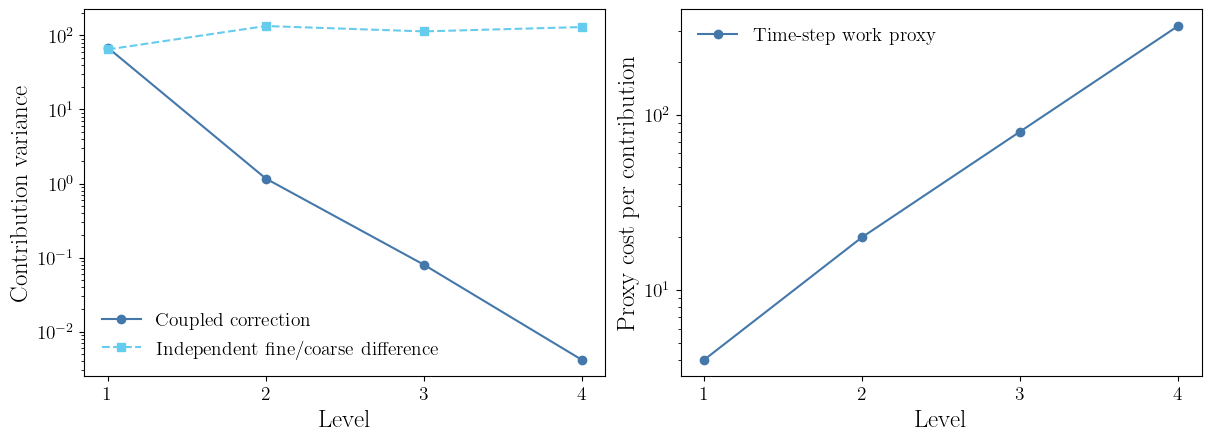

In [5]:
pilot_started = time.perf_counter()
pilot_variance, diagnostic_rows = [], []
for ell, d, cost in zip(levels, dimensions, proxy_cost):
    started = time.perf_counter()
    values = np.concatenate(list(contributions(ell, PILOT_N, 'IID', stream(2, ell))))
    elapsed = time.perf_counter()-started
    variance = values.var(ddof=1)
    pilot_variance.append(variance)
    direct_values = np.concatenate(list(contributions(ell, PILOT_N, 'IID', stream(3, ell), False)))
    if ell > 1:
        coarse_values = np.concatenate(list(contributions(ell-1, PILOT_N, 'IID', stream(4, ell), False)))
        independent_variance = direct_values.var(ddof=1)+coarse_values.var(ddof=1)
    else:
        independent_variance = direct_values.var(ddof=1)
    diagnostic_rows.append(dict(level=ell, steps=d, correction_mean=values.mean(),
                                coupled_variance=variance, independent_variance=independent_variance,
                                proxy_cost=cost, complete_batch_seconds=elapsed,
                                seconds_per_contribution=elapsed/PILOT_N))
direct_fine_pilot_variance = float(direct_values.var(ddof=1))  # Last fine-payoff diagnostic, at level L
pilot_variance = np.array(pilot_variance)
IID_PILOT_WORK = float(PILOT_N*proxy_cost.sum())
IID_SECTION_SECONDS = time.perf_counter()-pilot_started
# Additional independent-difference draws are explanatory diagnostics, not used for allocation.
diag = pd.DataFrame(diagnostic_rows).set_index('level')
IID_PILOT_SECONDS = float(diag.complete_batch_seconds.sum())
level_guide = pd.DataFrame({'fine_steps':dimensions,
    'coarse_steps':np.r_[0,dimensions[:-1]],
    'sampled_contribution':['base payoff']+['fine minus coarse']*(L-1),
    'proxy_cost':proxy_cost}, index=levels).rename_axis('level')
display(Markdown('**Level guide** — a zero coarse-step count means no coarse payoff at the base level.'))
display(level_guide)
display(Markdown('**Pilot measurements**'))
display(diag)
print(f'Allocation pilot: {IID_PILOT_WORK:,.0f} proxy work; pilot: {IID_PILOT_SECONDS:.3f} sec; complete diagnostic section: {IID_SECTION_SECONDS:.3f} sec')
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), constrained_layout=True)
axes[0].semilogy(levels, diag.coupled_variance, 'o-', label='Coupled correction')
axes[0].semilogy(levels, diag.independent_variance, 's--', label='Independent fine/coarse difference')
axes[0].set(xlabel='Level', ylabel='Contribution variance', xticks=levels)
axes[0].legend()
axes[1].semilogy(levels, diag.proxy_cost, 'o-', label='Time-step work proxy')
axes[1].set(xlabel='Level', ylabel='Proxy cost per contribution', xticks=levels)
axes[1].legend()
plt.show()

### Reading the pilot table

| Column | How to read it |
|:---|:---|
| `steps` | Fine-grid monitoring steps for this row |
| `correction_mean` | Estimated mean of $Y_\ell$; at level 1 this is the mean coarse payoff, not a difference |
| `coupled_variance` | Estimated $V_\ell=\operatorname{var}(Y_\ell)$ for **one contribution**, using a shared fine/coarse path |
| `independent_variance` | Estimated variance of a fine-minus-coarse difference if the two paths were independent: the two payoff variances add |
| `proxy_cost` | Time-step work for one complete contribution, as listed in the level guide |
| `complete_batch_seconds` | Measured time to construct, generate, transform, and evaluate this row's coupled pilot batch |
| `seconds_per_contribution` | That batch time divided by `PILOT_N`; a small-batch timing estimate, not a universal cost constant |

At the **finest level**, subtract the previous grid's payoff from the fine payoff. Its `proxy_cost` counts both evaluations. Compare that row's coupled and independent variances: their ratio measures the variance reduction from sharing the path.

The variance of the **estimated level mean** is smaller than the one-contribution variance:

$$
\operatorname{var}(\widehat\mu_\ell)=V_\ell/n_\ell.
$$

Thus the table does not yet tell us the final estimator variance: Part 4 chooses the $n_\ell$. A small correction mean alone does not imply a small variance or bound the remaining continuous-limit bias.

### Reading the two plots

- **Left:** the horizontal axis is level; the logarithmic vertical axis is one-contribution variance. The solid curve falls because shared paths make fine and coarse payoffs similar. The dashed curve shows how much variance would remain without that coupling. At level 1 both curves estimate the same coarse-payoff variance from different pilot draws, so they need not coincide exactly.
- **Right:** the horizontal axis is level; the logarithmic vertical axis is the time-step work proxy. Fine corrections cost more, even though their variances are smaller. This variance-versus-cost tradeoff is why Part 4 assigns different sample counts to the levels.

Measured seconds need not follow the proxy exactly: sampler construction, vectorization, and short-run timing overhead also matter. The independent-path comparisons are teaching diagnostics; the allocation pilot cost printed below the table counts only the coupled samples used to choose the allocation.

## 4. Equal point counts, equal work, optimal allocation, or single level?

Here **work is `proxy_cost` × sample count, added across levels**. Let $c_\ell$ be the `proxy_cost` value in level $\ell$ of the Part 3 table, and let $n_\ell$ be that level's final sample count. Then

$$
\texttt{final\_work}=\sum_{\ell=1}^L n_\ell\,\texttt{proxy\_cost}_\ell
=\sum_{\ell=1}^L n_\ell c_\ell.
$$

In the code, this is `(counts * proxy_cost).sum()`. For single-level IID, use `fine_cost` per sample because only the finest payoff is evaluated:

$$
\texttt{final\_work}=n\,\texttt{fine\_cost}.
$$

Pilot work is added separately to obtain total work.

At final-sample work $C$, the IID continuous optimum has
$$
w_\ell=\sqrt{V_\ell/c_\ell},\qquad
n_\ell=\frac{Cw_\ell}{\sum_k c_kw_k}.
$$

Every strategy receives the **same maximum total-work budget**. The table separates

$$
\texttt{total\_work}=\texttt{final\_work}+\texttt{pilot\_work}.
$$

- `final_work`: work used by the final samples that form the reported estimate
- `pilot_work`: allocation-pilot work; deducted from the optimal strategy's budget before choosing final samples
- `total_work`: the sum of those two charges
- `unused_work`: the budget left after integer rounding

These columns count **time-step work units**, a computational-work proxy. They are not measured seconds or exact CPU-operation counts. A direct $d$-step payoff costs $d$ proxy units; a coupled fine/coarse correction costs $d_{\mathrm{fine}}+d_{\mathrm{coarse}}$. Clock times are reported separately in Part 7.

Equal point counts and equal work shares are different designs. A small correction can receive fewer points without receiving negligible work. Equal-count, equal-work, and single-level IID need no allocation pilot. The optimum uses independent pilot variances and pays for that pilot within its total budget.

The **single-level IID** strategy spends its budget entirely on the same finest-grid payoff $P_{d_L}$. Its per-sample cost is `fine_cost`; a coupled correction also pays for the coarse payoff, as recorded in `proxy_cost`.

The predicted MSE and RMSE below concern **sampling error for the same fixed fine target**. They use the variance diagnostics from Part 3, not observed final errors. The fine-payoff variance diagnostic does not choose the single-level sample count, so it is separate teaching/assessment work rather than an allocation pilot. Part 7 supplies an empirical whole-estimator comparison.


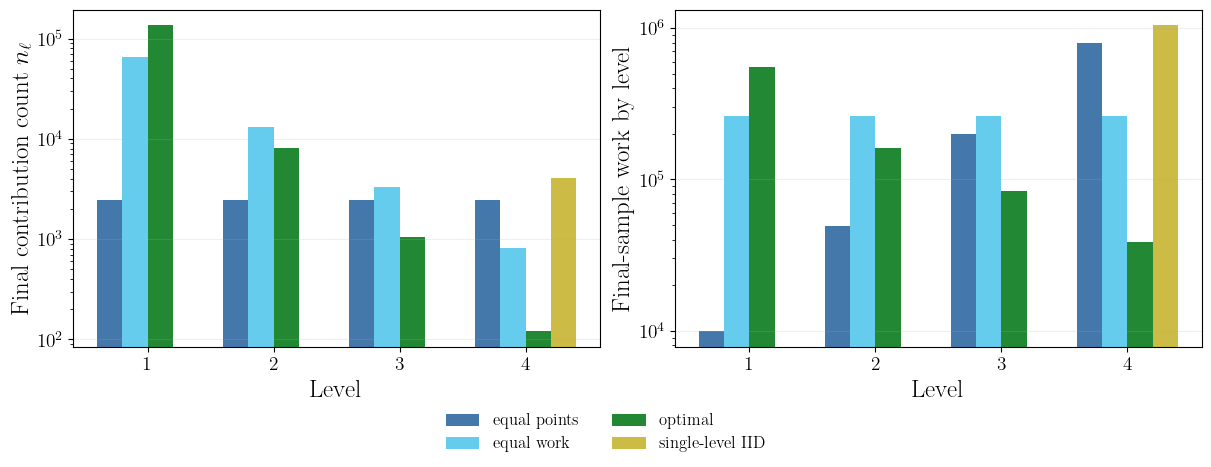

Maximum total-work budget for every strategy: 1,048,576 time-step work units


,final_work,pilot_work,total_work,unused_work,predicted_MSE,predicted_RMSE
design,,,,,,
equal points,1048552,0,1048552,24,0.028100,0.167631
equal work,1048444,0,1048444,132,0.001160,0.034059
optimal,831488,217088,1048576,0,0.000755,0.027468
single-level IID,1048576,0,1048576,0,0.016270,0.127555


In [6]:
def iid_allocation(budget, kind='optimal'):
    if kind == 'equal points':
        return np.full(L, max(1, int(budget//proxy_cost.sum())))
    if kind == 'equal work':
        return np.maximum(1, np.floor(budget/(L*proxy_cost))).astype(int)
    weights = np.sqrt(pilot_variance/proxy_cost)
    continuous = budget*weights / np.dot(proxy_cost, weights)
    counts = np.maximum(1, np.floor(continuous)).astype(int)
    if np.dot(counts, proxy_cost) > budget:
        raise ValueError('Budget cannot fund one contribution per level')
    # Spend the small rounding remainder where it reduces the variance model most.
    while True:
        affordable = proxy_cost <= budget-np.dot(counts, proxy_cost)
        if not affordable.any(): break
        gain = pilot_variance/(counts*(counts+1)*proxy_cost)
        counts[np.argmax(np.where(affordable, gain, -np.inf))] += 1
    return counts


allocation_budget = WORK_BUDGETS[0]
allocations = {kind:iid_allocation(allocation_budget-(IID_PILOT_WORK if kind=='optimal' else 0), kind)
               for kind in ['equal points','equal work','optimal']}

# Each entry contains point counts, work by level, allocation-pilot work,
# and the pilot prediction of sampling MSE for the fixed fine-grid mean.
designs = []
for kind,counts in allocations.items():
    pilot_work = IID_PILOT_WORK if kind=='optimal' else 0
    designs.append((kind, counts, counts*proxy_cost, pilot_work,
                    float(np.sum(pilot_variance/counts))))

single_count = int(allocation_budget//fine_cost)
single_counts = np.zeros(L, dtype=int)
single_counts[-1] = single_count
designs.append(('single-level IID', single_counts, single_counts*fine_cost, 0.,
                direct_fine_pilot_variance/single_count))

summary = []
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), constrained_layout=True)
for j,(kind,counts,work_by_level,pilot_work,mse) in enumerate(designs):
    offset=(j-1.5)*.20
    positive = counts>0  # Zero coarse-level counts have no bar on a log scale.
    axes[0].bar((levels+offset)[positive], counts[positive], width=.20, label=kind)
    axes[1].bar((levels+offset)[positive], work_by_level[positive], width=.20, label=kind)
    final_work = int(work_by_level.sum())
    total_work = final_work+int(pilot_work)
    assert total_work <= allocation_budget
    summary.append(dict(design=kind, final_work=final_work,
                        pilot_work=int(pilot_work), total_work=total_work,
                        unused_work=int(allocation_budget-total_work),
                        predicted_MSE=mse, predicted_RMSE=np.sqrt(mse)))
axes[0].set(xlabel='Level', ylabel=r'Final contribution count $n_\ell$', xticks=levels, yscale='log')
axes[1].set(xlabel='Level', ylabel='Final-sample work by level', xticks=levels, yscale='log')
for ax in axes:
    ax.grid(axis='y', which='major', alpha=.2)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='outside lower center', ncol=2, fontsize=12)
plt.show()
allocation_summary = pd.DataFrame(summary).set_index('design')
print(f'Maximum total-work budget for every strategy: {allocation_budget:,} time-step work units')
display(allocation_summary)


The single-level bars appear only at the finest level: every sample evaluates the finest-grid payoff. The three multilevel designs distribute contributions across the included levels. Their work plot shows **final-sample work only**; the table adds any pilot work to obtain `total_work`. Compare the predicted RMSE column at these nearly identical total-work charges; the lower value predicts better sampling accuracy for the same fine-grid target.

Both vertical axes are logarithmic, so major ticks such as $10^2$ and $10^3$ differ by a factor of ten. Read bar tops against those ticks, rather than interpreting their lengths from zero. Single-level coarse-level counts are zero and have no bar on this scale.

## 5. Randomized Sobol' needs a different allocation pilot

For $R$ independent randomizations, let $N_\ell$ be the points per run and $n_\ell=RN_\ell$ the **total** level contributions. If $M_{\ell,r}$ is the mean from one run, estimate the variance of their reported average by
$$
\widehat v_\ell(n_\ell)=\frac{\operatorname{var}_{\mathrm{sample}}(M_{\ell,0},\ldots,M_{\ell,R-1})}{R}.
$$
An IID output variance does not give this quantity. Hold $R$ fixed and pilot several $N$ values. Fit a common positive decay power in $v_\ell(n)\approx A_\ell^2 n^{-2p}$; then use $w_\ell=(A_\ell^2/c_\ell)^{1/(2p+1)}$.

The fitted rate is a noisy planning model. It does not prove a convergence order or justify an adaptive stopping rule. Powers-of-two rounding changes the ideal allocation. A fresh independent randomization is used for every level and every final run.

Common fitted p=0.881; planning model only
RQMC pilot: 759,808 proxy work; 0.492 sec


,individual_fitted_p,fitted_A_squared
level,,
1,1.174150,98.854292
2,1.114718,28.901268
3,0.524098,2.889031
4,0.647040,0.310263


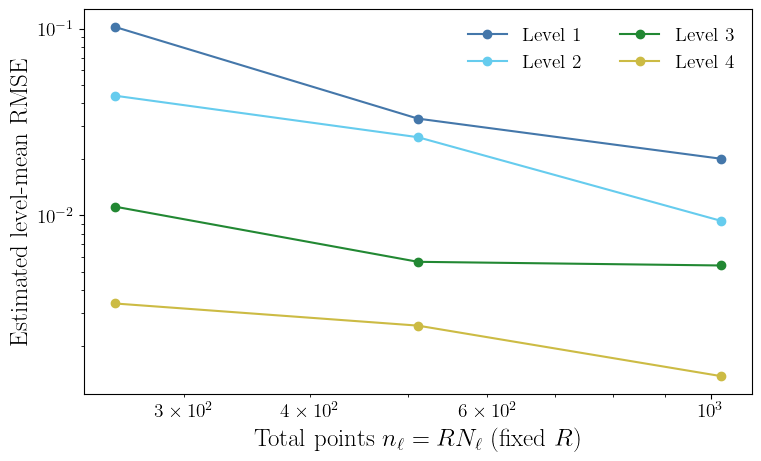

In [7]:
rqmc_pilot_started = time.perf_counter()
pilot_run_variances = np.empty((L, len(RQMC_PILOT_SIZES)))
for k,ell in enumerate(levels):
    for j,n in enumerate(RQMC_PILOT_SIZES):
        means = replicated_means(ell,n,R,(5,ell,j))
        pilot_run_variances[k,j] = means.var(ddof=1)/R
assert np.all(pilot_run_variances > 0)
total_pilot_counts = R*np.array(RQMC_PILOT_SIZES)
rate_by_level = np.array([-np.polyfit(np.log(total_pilot_counts),np.log(v),1)[0]/2
                          for v in pilot_run_variances])
p_rqmc = float(np.median(rate_by_level))
if p_rqmc <= 0:
    raise RuntimeError('Pilot does not support a positive common rate; increase pilot sizes/replications')
amplitude_squared = np.exp(np.mean(np.log(pilot_run_variances)
                                   + 2*p_rqmc*np.log(total_pilot_counts), axis=1))
RQMC_PILOT_WORK = float(total_pilot_counts.sum()*proxy_cost.sum())
RQMC_PILOT_SECONDS = time.perf_counter()-rqmc_pilot_started
print(f'Common fitted p={p_rqmc:.3f}; planning model only')
print(f'RQMC pilot: {RQMC_PILOT_WORK:,.0f} proxy work; {RQMC_PILOT_SECONDS:.3f} sec')
display(pd.DataFrame({'level':levels, 'individual_fitted_p':rate_by_level,
                      'fitted_A_squared':amplitude_squared}).set_index('level'))
fig, ax = plt.subplots(figsize=(7.5,4.5), constrained_layout=True)
for ell,variances in zip(levels,pilot_run_variances):
    ax.loglog(total_pilot_counts, np.sqrt(variances), 'o-',label=f'Level {ell}')
ax.set(xlabel=r'Total points $n_\ell=RN_\ell$ (fixed $R$)', ylabel='Estimated level-mean RMSE')
ax.legend(ncol=2)
plt.show()

def rqmc_allocation(budget):
    weights=(amplitude_squared/proxy_cost)**(1/(2*p_rqmc+1))
    continuous=budget*weights/np.dot(weights,proxy_cost)
    per_run=np.maximum(8,2**np.floor(np.log2(np.maximum(continuous/R,1)))).astype(int)
    if np.dot(R*per_run,proxy_cost)>budget:
        raise ValueError('Increase budget to fund the minimum Sobol designs')
    while True:
        counts=R*per_run
        added_work=counts*proxy_cost
        affordable=added_work <= budget-np.dot(counts,proxy_cost)
        if not affordable.any(): break
        gain=amplitude_squared*counts**(-2*p_rqmc)*(1-2**(-2*p_rqmc))/added_work
        per_run[np.argmax(np.where(affordable,gain,-np.inf))] *= 2
    return per_run

### Reading the Sobol' pilot output

Each curve in the preceding plot belongs to one level. The horizontal axis counts all $n_\ell=RN_\ell$ points used at that level, with $R$ fixed; the vertical axis estimates the RMSE of the average over those randomizations. Lower values mean less sampling variability for that level mean.

`individual_fitted_p` is the decay power fitted separately on a level; the common `p` is a summary used by the allocation model. `fitted_A_squared` gives that level's fitted amplitude. These are noisy pilot estimates. The IID variance column from Part 3 does not replace this pilot, because Sobol' points within a run are dependent.

## 6. Independent numerical reference for the finite target

Use many independent scrambled Sobol' runs at the **same finest grid** $d_L$. Report their average and estimated standard error. This is a numerical reference, not an exact value or a reference for the continuous-time limit.

For independent estimates $\widehat\mu$ and $\widehat\mu_{\mathrm{ref}}$, the expected squared discrepancy contains both variances. Thus reference uncertainty must be small compared with the displayed RMSE. We report it rather than silently subtracting a noisy variance estimate. Reference generation is validation work, excluded from estimator work budgets but included in total notebook execution time.

The printed standard error describes uncertainty in the reference price. It becomes the gray horizontal line in Part 7, allowing us to check whether the reference is accurate enough to judge the competing methods.

In [8]:
reference_started=time.perf_counter()
reference_runs=replicated_means(L, REF_N, REF_R, (6,), correction=False)
reference=float(reference_runs.mean())
reference_se=float(reference_runs.std(ddof=1)/np.sqrt(REF_R))
print(f'Finite-grid numerical reference mu_dL: {reference:.8f}')
print(f'Estimated reference SE: {reference_se:.3g}; {REF_R} runs of {REF_N:,} points')
print(f'Reference time: {time.perf_counter()-reference_started:.2f} sec (validation, not estimator work)')

Finite-grid numerical reference mu_dL: 5.76293702
Estimated reference SE: 0.000196; 16 runs of 32,768 points
Reference time: 3.73 sec (validation, not estimator work)


## 7. Compare complete estimators at the same work budgets

This is an **experimental check of the allocation predictions in Part 4**. Every method estimates the same finest-grid price $\mu_{d_L}$. The grid stays fixed here; approximation bias to the continuous-time limit is examined in Part 8.

### What the five methods do

| Method | How one price estimate is computed | Allocation pilot? |
|:---|:---|:---|
| Single-level IID | Average independent payoffs evaluated only on the finest grid | No |
| Single-level Sobol' | Average finest-grid payoffs using independently randomized Sobol' runs | No |
| MLMC equal points | Sum IID level means, using equal sample counts on every level | No |
| MLMC optimal | Sum IID level means, with counts chosen using the variance pilot | Yes |
| MLQMC pilot allocation | Sum randomized Sobol' level means, with counts chosen using the RQMC pilot | Yes |

All five receive the same **maximum work budget for one price estimate**. The allocation pilots count against that budget. `total_work` is the work actually used, including the pilot; Sobol' sample-size restrictions can leave some budget unused.

### What one plotted dot means

For each method and budget, compute `TRIALS` independent **whole price estimates**. The pilot and chosen allocation are held fixed across these repetitions; fresh final samples produce the different price estimates. With the default `TRIALS=12`, one dot summarizes 12 estimates, not 12 paths. Compare each estimate with the independent numerical reference from Part 6:

$$
\texttt{empirical\_RMSE}
=\left[\frac{1}{\texttt{TRIALS}}
\sum_{k=0}^{\texttt{TRIALS}-1}
\left(\widehat\mu^{(k)}-\widehat\mu_{\mathrm{ref}}\right)^2\right]^{1/2}.
$$

Smaller RMSE means the repeated estimates lie closer to the same reference price. The reference is numerical, not exact, so its uncertainty also contributes to these discrepancies.

`R` and `TRIALS` have different jobs: `R` counts independent Sobol' randomizations **inside one reported price**; `TRIALS` counts repeated reported prices used to assess accuracy. Work for the `R` runs is already included in each method's budget. The outer `TRIALS` repetitions and the numerical reference are assessment work, not part of the per-estimate budget.

Clock times include construction, generation, transformations, and payoff evaluation. `complete_seconds` is average final-run time plus the allocation-pilot time once per hypothetical estimate. The pilot is charged once, rather than amortized over `TRIALS`; plotting and reference computations contribute separately to total notebook runtime.


,method,budget,total_work,pilot_work,unused_work,empirical_RMSE,complete_seconds
0,Single-level IID,1048576,1048576.0,0.0,0.0,0.124438,0.0444
1,Single-level Sobol',1048576,1048576.0,0.0,0.0,0.006934,0.1431
2,MLMC equal points,1048576,1048552.0,0.0,24.0,0.206236,0.0417
3,MLMC optimal,1048576,1048576.0,217088.0,0.0,0.022860,0.0606
4,MLQMC pilot allocation,1048576,1038336.0,759808.0,10240.0,0.006566,0.6719
5,Single-level IID,2097152,2097152.0,0.0,0.0,0.103195,0.0714
6,Single-level Sobol',2097152,2097152.0,0.0,0.0,0.003778,0.1750
7,MLMC equal points,2097152,2097104.0,0.0,48.0,0.091144,0.0625
8,MLMC optimal,2097152,2097152.0,217088.0,0.0,0.015272,0.0920
9,MLQMC pilot allocation,2097152,2004992.0,759808.0,92160.0,0.002356,0.6834


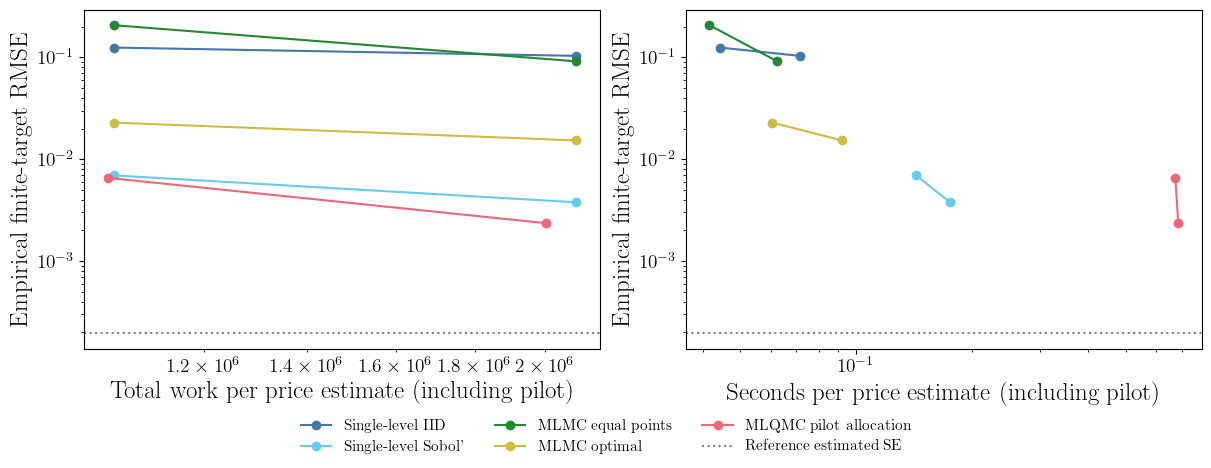

Reference SE / smallest empirical RMSE: 0.083
With only a few budgets and finite trials, these curves illustrate behavior, not asymptotic-rate proofs


**Read one comparison:** at the first budget of 1,048,576 work units, single-level IID has empirical RMSE **0.1244**, while optimal IID MLMC has **0.02286** (about 5.4 times smaller). Their measured times are 0.0444 and 0.0606 seconds per estimate, respectively. The work comparison and clock-time comparison answer different questions.

In [9]:
def ml_estimate(counts, method, labels):
    total=0.
    for ell,count in zip(levels,counts):
        if method=='IID':
            total+=estimate(ell,int(count),'IID',stream(*labels,ell))
        else:
            total+=replicated_means(ell,int(count),R,(*labels,ell)).mean()
    return total

records=[]
for bi,budget in enumerate(WORK_BUDGETS):
    n_iid=int(budget//fine_cost)
    n_sobol=2**int(np.floor(np.log2(budget/(R*fine_cost))))
    equal=iid_allocation(budget,'equal points')
    optimal=iid_allocation(budget-IID_PILOT_WORK)
    rqmc=rqmc_allocation(budget-RQMC_PILOT_WORK)
    designs=[
      ('Single-level IID',np.array([n_iid]),0.,0.,n_iid*fine_cost),
      ("Single-level Sobol'",np.array([n_sobol]),0.,0.,R*n_sobol*fine_cost),
      ('MLMC equal points',equal,0.,0.,np.dot(equal,proxy_cost)),
      ('MLMC optimal',optimal,IID_PILOT_WORK,IID_PILOT_SECONDS,np.dot(optimal,proxy_cost)),
      ('MLQMC pilot allocation',rqmc,RQMC_PILOT_WORK,RQMC_PILOT_SECONDS,np.dot(R*rqmc,proxy_cost))]
    for mi,(name,counts,pilot_work,pilot_seconds,final_work) in enumerate(designs):
        estimates=[]; durations=[]
        for trial in range(TRIALS):
            labels=(7,bi,mi,trial)
            started=time.perf_counter()
            if name=='Single-level IID': result=estimate(L,n_iid,'IID',stream(*labels),False)
            elif name=="Single-level Sobol'":
                result=replicated_means(L,n_sobol,R,labels,False).mean()
            else: result=ml_estimate(counts,'Sobol' if name.startswith('MLQMC') else 'IID',labels)
            estimates.append(result);durations.append(time.perf_counter()-started)
        estimates=np.array(estimates)
        discrepancy_rmse=float(np.sqrt(np.mean((estimates-reference)**2)))
        records.append(dict(method=name, budget=budget, pilot_work=pilot_work,
                            final_work=final_work, total_work=final_work+pilot_work,
                            unused_work=budget-final_work-pilot_work,
                            empirical_RMSE=discrepancy_rmse,
                            trial_SD=estimates.std(ddof=1), mean_estimate=estimates.mean(),
                            complete_seconds=np.mean(durations)+pilot_seconds))
results=pd.DataFrame(records)
display(results[['method','budget','total_work','pilot_work','unused_work',
                 'empirical_RMSE','complete_seconds']].round({'empirical_RMSE':6,'complete_seconds':4}))
fig,axes=plt.subplots(1,2,figsize=(12,4.6),constrained_layout=True)
for name,frame in results.groupby('method',sort=False):
    axes[0].loglog(frame.total_work,frame.empirical_RMSE,'o-',label=name)
    axes[1].loglog(frame.complete_seconds,frame.empirical_RMSE,'o-',label=name)
for ax in axes:
    ax.axhline(reference_se,color='gray',linestyle=':',label='Reference estimated SE')
    ax.set_ylabel('Empirical finite-target RMSE')
axes[0].set_xlabel('Total work per price estimate (including pilot)')
axes[1].set_xlabel('Seconds per price estimate (including pilot)')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='outside lower center', ncol=3, fontsize=11)
plt.show()
print(f'Reference SE / smallest empirical RMSE: {reference_se/results.empirical_RMSE.min():.3f}')
print('With only a few budgets and finite trials, these curves illustrate behavior, not asymptotic-rate proofs')

# Generate an interpretation from the saved results, so it follows parameter changes.
first_budget = results.budget.min()
first = results[results.budget==first_budget].set_index('method')
single = first.loc['Single-level IID']
multilevel = first.loc['MLMC optimal']
display(Markdown(
    f'**Read one comparison:** at the first budget of {first_budget:,.0f} work units, '
    f'single-level IID has empirical RMSE **{single.empirical_RMSE:.4g}**, '
    f'while optimal IID MLMC has **{multilevel.empirical_RMSE:.4g}** '
    f'(about {single.empirical_RMSE/multilevel.empirical_RMSE:.2g} times smaller). '
    f'Their measured times are {single.complete_seconds:.3g} and '
    f'{multilevel.complete_seconds:.3g} seconds per estimate, respectively. '
    'The work comparison and clock-time comparison answer different questions.'))


### Reading the table and both plots

| Column | Meaning |
|:---|:---|
| `method` | One of the five procedures listed above |
| `budget` | Maximum proxy work allowed for **one** reported price |
| `total_work` | Actual final-sample work plus allocation-pilot work |
| `pilot_work` | The pilot part already included in `total_work`; do not add it again |
| `unused_work` | `budget - total_work`, mainly from sample-size rounding |
| `empirical_RMSE` | Error summary over the `TRIALS` independent price estimates |
| `complete_seconds` | Average seconds for one final run, plus its pilot time |

- **Left plot:** lower means smaller sampling error; farther right means more work. At comparable horizontal positions, the lower curve gives better accuracy per work budget. Work is counted using `proxy_cost` times sample counts, with pilot work included.
- **Right plot:** the same error values are plotted against measured seconds. At comparable times, lower means better accuracy in that time. A method that is efficient in proxy work can still take longer because setup and implementation overhead matter.
- **Dots and lines:** each dot summarizes repeated whole price estimates at one budget. Lines merely connect the two budgets for the same method; they are not the history of a single adaptive run.
- **Gray dotted line:** estimated standard error of the numerical reference from Part 6. It is neither a requested tolerance nor an approximation-bias floor. Results close to it need a more accurate reference for a clear comparison.

This section measures **sampling error on one fixed finest grid**. Part 8 changes grids to investigate approximation bias; Part 9 lets adaptive algorithms choose both counts and grids.

### What the saved default comparison shows

Compare **MLQMC pilot allocation** with **single-level randomized Sobol'**:

- At the smaller budget, their empirical RMSEs are very similar; there is no clear practical improvement from MLQMC in this experiment.
- At the larger budget, MLQMC gives a modest reduction in sampling RMSE at comparable proxy work.
- In measured seconds, MLQMC takes longer at both budgets with its pilot included. This run shows an accuracy-per-work benefit at the larger budget, rather than a clock-time advantage.

The IID comparison is separate: optimal IID MLMC improves substantially on single-level IID here. Equal-point MLMC can still waste work on expensive corrections. These observations describe the saved finite experiment; the two budgets and finite repetitions do not establish a universal ranking or a convergence-rate proof.

### Where the IID and MLQMC samples go

These are **allocation bar charts**, not error plots. They use the larger work budget and compare optimal IID MLMC with pilot-allocated MLQMC.

- **Left:** total final contribution counts on each level. In the table, `Sobol_points_per_run` is $N_\ell$ and `Sobol_total_points` is $RN_\ell$. The bars use the total counts, so both methods count all evaluations.
- **Right:** final work on each level, calculated as total count times `proxy_cost`. Pilot work was deducted before allocating these final samples and is not included in the bars.

Both vertical axes are logarithmic so small fine-level bars remain visible. Read values at the bar tops; a change from $10^2$ to $10^3$ is multiplication by ten. These plots show **where work is spent**. The preceding error plots show what accuracy that allocation achieves.

,IID_total_points,Sobol_points_per_run,Sobol_total_points,IID_level_work,Sobol_level_work
level,,,,,
1,310036,8192,65536,1240144.0,262144.0
2,18140,2048,16384,362800.0,327680.0
3,2380,512,4096,190400.0,327680.0
4,271,128,1024,86720.0,327680.0


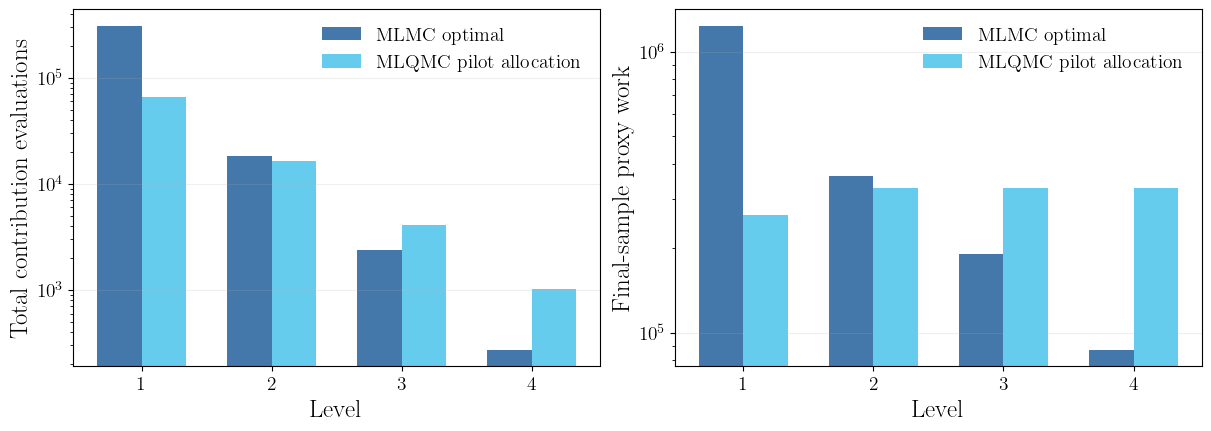

In [10]:
budget=WORK_BUDGETS[-1]
counts_iid=iid_allocation(budget-IID_PILOT_WORK)
counts_per_run=rqmc_allocation(budget-RQMC_PILOT_WORK)
display(pd.DataFrame({'level':levels, 'IID_total_points':counts_iid,
                      'Sobol_points_per_run':counts_per_run,
                      'Sobol_total_points':R*counts_per_run,
                      'IID_level_work':counts_iid*proxy_cost,
                      'Sobol_level_work':R*counts_per_run*proxy_cost}).set_index('level'))
fig,axes=plt.subplots(1,2,figsize=(12,4.2),constrained_layout=True)
for offset,name,counts in [(-.17,'MLMC optimal',counts_iid),(.17,'MLQMC pilot allocation',R*counts_per_run)]:
    axes[0].bar(levels+offset,counts,width=.34,label=name)
    axes[1].bar(levels+offset,counts*proxy_cost,width=.34,label=name)
axes[0].set(xlabel='Level',ylabel='Total contribution evaluations',xticks=levels,yscale='log')
axes[1].set(xlabel='Level',ylabel='Final-sample proxy work',xticks=levels,yscale='log')
for ax in axes:
    ax.grid(axis='y',which='major',alpha=.2)
axes[0].legend();axes[1].legend()
plt.show()

## 8. Sampling error is not continuous-limit bias

Use the same parameters on grids both coarser and finer than $d_L$. Estimate adjacent correction means from independent randomized Sobol' runs, and add or subtract them from the independent $d_L$ reference. The coarse grids make the resolution effect visible; refinements beyond $d_L$ probe what remains.

The estimator is unbiased for the finest finite price. When error is measured relative to the **limiting price** $\mu$,
$$
\operatorname{MSE}(\widehat\mu)
=b_L^2+\operatorname{var}(\widehat\mu).
$$
More samples at fixed $L$ reduce variance but leave $b_L$ unchanged. A small last correction is only a diagnostic: it does not bound the entire uncomputed tail. Estimated standard errors below describe randomization uncertainty, not an unknown discretization-bias bound.

Plot bars are two estimated randomization standard errors, not certified intervals. The rows share the numerical reference and some correction estimates, so the plotted errors are correlated across resolutions.

In the table, `steps` is the actual grid resolution, `price_estimate` is its estimated mean price, and `randomization_SE` describes sampling uncertainty in that displayed mean. The left-to-right change of price with grid resolution is a bias diagnostic. The bars on the plot show two estimated standard errors of the displayed means; they do not bound the uncomputed tail beyond the finest grid.

,level,steps,price_estimate,randomization_SE,correction_mean,correction_SE
0,1,4,5.731230,0.002855,NaN,NaN
1,2,16,5.760710,0.001123,0.029480,0.002625
2,3,64,5.762983,0.000574,0.002273,0.000965
3,4,256,5.762937,0.000196,-0.000046,0.000539
4,5,1024,5.762822,0.000235,-0.000115,0.000129


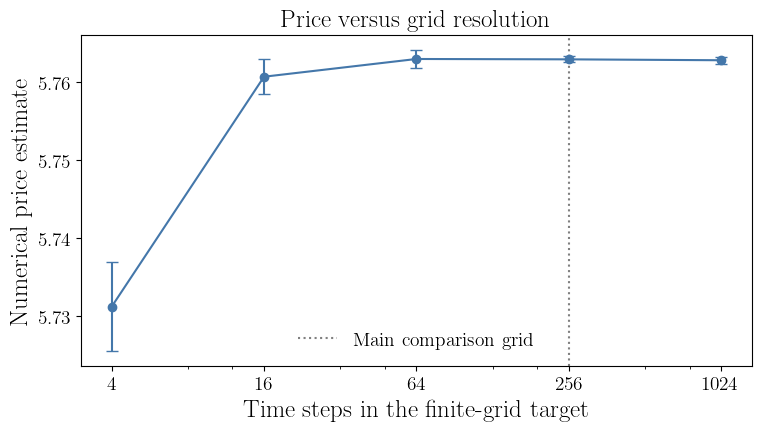

Refinement diagnostic time: 7.34 sec


In [11]:
bias_started=time.perf_counter()
correction_diagnostics={}
for ell in REFINE_LEVELS:
    if ell <= 1: continue
    runs=replicated_means(ell,REFINE_N,REFINE_R,(8,ell))
    correction_diagnostics[ell]=(float(runs.mean()),float(runs.std(ddof=1)/np.sqrt(REFINE_R)))
prices={L:(reference,reference_se**2)}
for ell in range(L,1,-1):
    mean,se=correction_diagnostics[ell]
    prices[ell-1]=(prices[ell][0]-mean,prices[ell][1]+se**2)
for ell in range(L+1,max(REFINE_LEVELS)+1):
    mean,se=correction_diagnostics[ell]
    prices[ell]=(prices[ell-1][0]+mean,prices[ell-1][1]+se**2)
bias_rows=[]
for ell in REFINE_LEVELS:
    mean,se=correction_diagnostics.get(ell,(np.nan,np.nan))
    price,variance=prices[ell]
    bias_rows.append(dict(level=ell,steps=REFINEMENT**ell,price_estimate=price,
                          randomization_SE=np.sqrt(variance),correction_mean=mean,correction_SE=se))
bias_table=pd.DataFrame(bias_rows)
display(bias_table)
fig,ax=plt.subplots(figsize=(7.5,4.2),constrained_layout=True)
ax.errorbar(bias_table.steps,bias_table.price_estimate,
            yerr=2*bias_table.randomization_SE,fmt='o-',capsize=4)
ax.axvline(REFINEMENT**L,color='gray',linestyle=':',label='Main comparison grid')
ax.set_xscale('log',base=REFINEMENT)
ax.set_xticks([REFINEMENT**ell for ell in REFINE_LEVELS])
ax.set_xticklabels([str(REFINEMENT**ell) for ell in REFINE_LEVELS])
ax.set(xlabel='Time steps in the finite-grid target',ylabel='Numerical price estimate',
       title='Price versus grid resolution')
ax.legend()
plt.show()
print(f'Refinement diagnostic time: {time.perf_counter()-bias_started:.2f} sec')

## 9. Optional: QMCPy's adaptive and continuation algorithms

Set `RUN_CONTINUATION=True` in the parameter cell to run this section. `CubMLMC` and `CubMLQMC` adapt the allocation **and finest level**, using estimated bias. Their native hierarchy refines by two, starting from four monitoring steps, rather than the factor-four hierarchy used in the main experiment. Their continuation variants first solve looser problems to learn allocation and refinement behavior.

These runs target the continuous-limit price under an estimated bias model; they are not part of the fixed-$L$ benchmark. Request `rmse_tol` explicitly. It is an algorithmic target, not a verified finite-sample RMSE guarantee. Fresh samplers keep runs independent. The sample/level limits bound the demonstration; inspect warnings before claiming a tolerance was achieved.

`data.n_level` counts IID contributions for MLMC, but points **per replication** for MLQMC. QMCPy's internal refinement level starts at zero, whereas the notebook's levels start at one.

Read the optional table as separate adaptive runs, not another equal-budget comparison: `price` is the returned estimate, `level_count` is how many levels the solver used, `total_contributions` counts all level evaluations (including Sobol' randomizations), and `complete_seconds` is measured time. A single realized estimate need not fall within one requested RMSE tolerance of the unknown limiting price.

In [12]:
if RUN_CONTINUATION:
    import warnings
    adaptive_rows=[]
    for i,name in enumerate(['CubMLMC','CubMLMCCont','CubMLQMC','CubMLQMCCont']):
        use_qmc='QMC' in name
        distribution=(qp.DigitalNetB2(seed=stream(9,i),replications=R,randomize='LMS DS')
                      if use_qmc else qp.IIDStdUniform(seed=stream(9,i)))
        integrand=qp.FinancialOption(distribution,**MODEL)
        stopper=getattr(qp,name)(integrand,rmse_tol=.03,n_init=128,
                                 n_limit=2**20,levels_max=7)
        started=time.perf_counter()
        with warnings.catch_warnings(record=True) as notices:
            solution,data=stopper.integrate()
        seconds=time.perf_counter()-started
        totals=np.array(data.n_level)*(R if use_qmc else 1)
        adaptive_rows.append(dict(method=name,price=float(solution),
                                  level_count=len(totals),total_contributions=int(totals.sum()),
                                  complete_seconds=seconds,
                                  warnings='; '.join(str(w.message) for w in notices)))
        print(name, 'total contributions by level:',totals)
    display(pd.DataFrame(adaptive_rows).set_index('method'))
else:
    print('Optional adaptive/continuation comparison skipped; set RUN_CONTINUATION=True and Run All to include it')

Optional adaptive/continuation comparison skipped; set RUN_CONTINUATION=True and Run All to include it


## Questions to discuss

1. Why must the two payoff discretizations share a Brownian path within each correction?
2. Why do independent sample sets between levels simplify the variance calculation?
3. Which design gives equal point counts? Which gives equal work? How do the optimal designs differ?
4. What does the RQMC pilot estimate that an IID contribution variance cannot supply?
5. When can pilot overhead outweigh multilevel savings at a modest budget?
6. What remains uncertain after the finite-grid sampling RMSE becomes very small?

The construction can be changed to randomized lattice points in `sampler`. Refit the RQMC pilot and rerun the entire notebook; do not carry fitted Sobol' amplitudes or rates across methods.

## Sources

- [QMCPy multilevel option-pricing notebook](https://qmcsoftware.org/qmcpy/demos/asian-option-mlqmc/), the initial comparison adapted here
- [QMCPy FinancialOption documentation](https://qmcsoftware.org/qmcpy/api/integrands/), for coupled coarse/fine payoffs and averaging conventions
- [QMCPy stopping criteria](https://qmcsoftware.org/qmcpy/api/stopping_criteria/), for MLMC, MLQMC, and continuation interfaces
- [Giles (2015), Multilevel Monte Carlo methods](https://people.maths.ox.ac.uk/gilesm/files/acta15.pdf)
- [Giles and Waterhouse, Multilevel quasi-Monte Carlo path simulation](https://people.maths.ox.ac.uk/gilesm/files/radon.pdf)

Saved timings describe the machine that executed the notebook. Rerun for classroom timings; the final cell reports all setup, diagnostic, reference, and experimental execution time.

In [13]:
notebook_elapsed = time.perf_counter() - NOTEBOOK_START_TIME
notebook_minutes, notebook_seconds = divmod(notebook_elapsed, 60)
print("Total execution time for this notebook is "
      f"{int(notebook_minutes)} min {notebook_seconds:.1f} sec.")

Total execution time for this notebook is 0 min 37.7 sec.
